# 05 — Selección, evaluación final y Model Registry

La selección de champion y challenger se hace con CV. Solo esas dos opciones se evalúan una vez en el holdout. El RMSE del holdout no se usa para volver a elegir el modelo.

## Límite de recursos observado

Las 30 configuraciones de Random Forest completaron su CV, pero el entorno no pudo serializar el bosque final con bootstrap sin límite. Para cerrar la evaluación de forma reproducible, se valida por CV una variante de recursos limitados (`max_samples=4096`): cada árbol se ajusta con 4.096 filas extraídas de toda la partición de entrenamiento. La desviación se registra en MLflow; la selección final se basa en el CV de esta variante y el RMSE del holdout se usa solo para reportar desempeño.

In [1]:
from pathlib import Path
import ast
import gc
import os
import sys
import time
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from mlflow.entities import ViewType
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_validate
from src.business_metrics import COELUTION_WINDOW_MIN, calibrate_pairwise_interval, coelution_proxy_metrics, compare_alert_rules
from src.datos import load_snapshot
from src.experiments import EXPERIMENT_NAME, MODEL_PIP_REQUIREMENTS, SCORING, WORKFLOW_VERSION, _git_commit, configure_tracking
from src.pipeline import make_default_models, make_search_spaces, make_model_pipeline, chromatographic_condition_groups, model_inputs, valid_smiles_mask
from src.splits import create_or_load_holdout, stratified_compound_sample

frame, metadata = load_snapshot()
valid = valid_smiles_mask(frame)
all_data = frame.loc[valid & frame["inchikey"].notna()].reset_index(drop=True)
train, test, split_metadata = create_or_load_holdout(all_data, source_sha256=metadata["sha256"])
selection_sample, sample_metadata = stratified_compound_sample(train, max_compounds=12_000, random_state=42)
X_oof, y_oof, groups_oof = model_inputs(selection_sample)
train_rows, holdout_rows = len(train), len(test)
del frame, all_data, valid, selection_sample
gc.collect()
X_train, y_train, groups_train = model_inputs(train)
X_test, y_test, groups_test = model_inputs(test)
del train, test
gc.collect()
final_metadata = {**metadata, "source_rows": metadata["rows"], "rows": train_rows, "training_sample_sha256": sample_metadata["sha256"], "sampling_method": sample_metadata["method"], "sampling_seed": sample_metadata["random_state"]}
tuning_table = pd.read_csv(PROJECT_ROOT / "docs" / "tuning.csv")
configure_tracking()
client = MlflowClient()
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
model_name = "qsrr-predict-modelo"
best_per_family = tuning_table.sort_values("cv_rmse_mean").groupby("family", as_index=False).first()
best_per_family["tuned_best_cv_rmse_mean"] = best_per_family["cv_rmse_mean"]
best_per_family["tuned_best_cv_rmse_std"] = best_per_family["cv_rmse_std"]
def parse_parameter(value, candidates):
    if value == "None":
        return None
    template = next((candidate for candidate in candidates if candidate is not None), None) if isinstance(candidates, list) else None
    if isinstance(template, tuple):
        return ast.literal_eval(value)
    if template is not None:
        return type(template)(value)
    return float(value)

rf_row = best_per_family.loc[best_per_family["family"].eq("random_forest")].iloc[0]
rf_search_space = make_search_spaces()["random_forest"]
rf_best_parameters = {
    name: parse_parameter(client.get_run(rf_row["run_id"]).data.params[name], candidates)
    for name, candidates in rf_search_space.items()
}
rf_resource_rows = 4_096
existing_rf_resource_runs = client.search_runs(
    [experiment.experiment_id],
    filter_string=(
        "tags.phase = 'resource_validation' AND tags.model_family = 'random_forest' "
        f"AND tags.training_sample_sha256 = '{sample_metadata['sha256']}'"
    ),
    run_view_type=ViewType.ALL,
    max_results=100,
)
finished_rf_resource_runs = [run for run in existing_rf_resource_runs if run.info.status == "FINISHED"]
if finished_rf_resource_runs:
    rf_resource_run = max(finished_rf_resource_runs, key=lambda item: item.info.start_time)
    rf_resource_cv_rmse = rf_resource_run.data.metrics["resource_adjusted_cv_rmse_mean"]
    rf_resource_cv_std = rf_resource_run.data.metrics["resource_adjusted_cv_rmse_std"]
else:
    from src.pipeline import clear_feature_caches
    clear_feature_caches()
    rf_cv_model = make_model_pipeline(make_default_models()["random_forest"])
    rf_cv_model.set_params(**rf_best_parameters, regressor__max_samples=rf_resource_rows)
    rf_resource_scores = cross_validate(
        rf_cv_model, X_oof, y_oof, groups=groups_oof,
        cv=GroupKFold(n_splits=5), scoring=SCORING, n_jobs=1,
        error_score="raise",
    )
    rf_resource_cv_rmse = float((-rf_resource_scores["test_rmse"]).mean())
    rf_resource_cv_std = float((-rf_resource_scores["test_rmse"]).std(ddof=1))
    with mlflow.start_run(run_name="resource_validation_random_forest"):
        mlflow.set_tags({
            "phase": "resource_validation", "model_family": "random_forest",
            "workflow_version": WORKFLOW_VERSION,
            "git_commit": _git_commit(), "data_sha256": metadata["sha256"],
            "training_sample_sha256": sample_metadata["sha256"],
            "validation": "GroupKFold by inchikey on training sample only",
            "resource_profile": f"max_samples={rf_resource_rows}",
        })
        mlflow.log_param("tuning_best_run_id", rf_row["run_id"])
        mlflow.log_param("training_sample_rows", sample_metadata["rows"])
        mlflow.log_param("final_bootstrap_rows", rf_resource_rows)
        mlflow.log_params(rf_best_parameters)
        mlflow.log_metrics({
            "resource_adjusted_cv_rmse_mean": rf_resource_cv_rmse,
            "resource_adjusted_cv_rmse_std": rf_resource_cv_std,
        })
best_per_family.loc[best_per_family["family"].eq("random_forest"), "cv_rmse_mean"] = rf_resource_cv_rmse
best_per_family.loc[best_per_family["family"].eq("random_forest"), "cv_rmse_std"] = rf_resource_cv_std
finalists = best_per_family.nsmallest(2, "cv_rmse_mean").copy()
display(finalists[["family", "configuration", "cv_rmse_mean", "cv_rmse_std", "run_id"]])
print({"random_forest_resource_adjusted_cv_rmse": rf_resource_cv_rmse, "max_samples": rf_resource_rows})
print({"full_train_rows": len(y_train), "full_grouped_holdout_rows": len(y_test), "selection_sample_compounds": sample_metadata["compounds"], "selection_sample_rows": sample_metadata["rows"]})
trained = {}
final_results = []

,family,configuration,cv_rmse_mean,cv_rmse_std,run_id
0,hist_gradient_boosting,9,2.591868,0.249749,bed738a932bf4200af0654fd3e25fc93
2,random_forest,23,2.593382,0.216498,b2b57d876e3d4a9494d37c4a066388d4


{'random_forest_resource_adjusted_cv_rmse': 2.5933822306253544, 'max_samples': 4096}
{'full_train_rows': 122370, 'full_grouped_holdout_rows': 30216, 'selection_sample_compounds': 12000, 'selection_sample_rows': 19406}


In [2]:
existing_final_runs = client.search_runs(
    [experiment.experiment_id],
    filter_string=(
        f"tags.phase = 'final' AND tags.workflow_version = '{WORKFLOW_VERSION}' "
        f"AND tags.training_sample_sha256 = '{sample_metadata['sha256']}'"
    ),
    run_view_type=ViewType.ALL,
    max_results=100,
)
model_versions = client.search_model_versions(f"name='{model_name}'")
for _, row in finalists.iterrows():
    family = row["family"]
    expected_resource_profile = (
        f"random_forest max_samples={rf_resource_rows}; all training rows are bootstrap population"
        if family == "random_forest" else "full-training refit in Codespace"
    )
    reusable = [
        run for run in existing_final_runs
        if run.info.status == "FINISHED"
        and run.data.tags.get("model_family") == family
        and run.data.tags.get("resource_profile") == expected_resource_profile
    ]
    if reusable:
        run = max(reusable, key=lambda item: item.info.start_time)
        model = mlflow.sklearn.load_model(f"runs:/{run.info.run_id}/model")
        prediction = model.predict(X_test)
        version = next(item for item in model_versions if item.run_id == run.info.run_id)
        metrics = {
            name: run.data.metrics[name]
            for name in (
                "full_train_rmse", "full_train_mae", "holdout_rmse", "holdout_mae",
                "fit_seconds_full_train", "prediction_seconds_full_holdout",
            )
        }
        metrics["selection_sample_cv_rmse_mean"] = float(row["cv_rmse_mean"])
        metrics["selection_sample_cv_rmse_std"] = float(row["cv_rmse_std"])
        trained[family] = {
            "prediction": prediction, "run_id": run.info.run_id,
            "version": str(version.version), **metrics,
        }
        final_results.append({"family": family, "run_id": run.info.run_id, **metrics})
        del model, prediction
        from src.pipeline import clear_feature_caches
        clear_feature_caches()
        gc.collect()
        continue

    search_parameters = make_search_spaces()[family]
    if family == "random_forest":
        best_parameters = rf_best_parameters.copy()
    else:
        logged_parameters = client.get_run(row["run_id"]).data.params
        best_parameters = {
            name: parse_parameter(logged_parameters[name], candidates)
            for name, candidates in search_parameters.items()
        }
    model = make_model_pipeline(make_default_models()[family])
    model.set_params(**best_parameters)
    if family == "random_forest":
        model.set_params(regressor__max_samples=rf_resource_rows)

    fit_start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - fit_start
    train_prediction = model.predict(X_train)
    predict_start = time.perf_counter()
    prediction = model.predict(X_test)
    prediction_seconds = time.perf_counter() - predict_start
    metrics = {
        "full_train_rmse": float(root_mean_squared_error(y_train, train_prediction)),
        "full_train_mae": float(mean_absolute_error(y_train, train_prediction)),
        "holdout_rmse": float(root_mean_squared_error(y_test, prediction)),
        "holdout_mae": float(mean_absolute_error(y_test, prediction)),
        "fit_seconds_full_train": float(fit_seconds),
        "prediction_seconds_full_holdout": float(prediction_seconds),
        "selection_sample_cv_rmse_mean": float(row["cv_rmse_mean"]),
        "selection_sample_cv_rmse_std": float(row["cv_rmse_std"]),
    }
    resource_profile = (
        f"random_forest max_samples={rf_resource_rows}; all training rows are bootstrap population"
        if family == "random_forest" else "full-training refit in Codespace"
    )
    with mlflow.start_run(run_name=f"final_full_train_{family}"):
        mlflow.set_tags({
            "phase": "final", "model_family": family,
            "workflow_version": WORKFLOW_VERSION, "git_commit": _git_commit(),
            "data_tables": metadata["source_tables"],
            "data_snapshot_read_at_utc": metadata["snapshot_read_at_utc"],
            "data_sha256": metadata["sha256"],
            "training_sample_sha256": sample_metadata["sha256"],
            "sampling_method": sample_metadata["method"],
            "sampling_seed": str(sample_metadata["random_state"]),
            "training_scope": "all rows in full grouped train partition",
            "holdout_scope": "all rows in full grouped holdout partition",
            "resource_profile": resource_profile,
            "validation": "selection GroupKFold by inchikey; final full grouped holdout",
            "random_state": "42",
        })
        mlflow.log_param("tuning_run_id", row["run_id"])
        mlflow.log_param("source_rows", final_metadata["source_rows"])
        mlflow.log_param("training_partition_rows", final_metadata["rows"])
        mlflow.log_param("training_sample_rows", sample_metadata["rows"])
        mlflow.log_param("full_training_rows", train_rows)
        mlflow.log_param("full_holdout_rows", holdout_rows)
        if family == "random_forest":
            mlflow.log_param("final_resource_max_samples", rf_resource_rows)
        mlflow.log_params(best_parameters)
        mlflow.log_metrics(metrics)
        signature = infer_signature(X_train.head(5), model.predict(X_train.head(5)))
        mlflow.sklearn.log_model(model, artifact_path="model", signature=signature, input_example=X_train.head(5), code_paths=["src"], pip_requirements=MODEL_PIP_REQUIREMENTS)
        final_run_id = mlflow.active_run().info.run_id
    version = mlflow.register_model(f"runs:/{final_run_id}/model", model_name)
    trained[family] = {"prediction": prediction, "run_id": final_run_id, "version": str(version.version), **metrics}
    final_results.append({"family": family, "run_id": final_run_id, **metrics})
    del model, train_prediction, prediction
    from src.pipeline import clear_feature_caches
    clear_feature_caches()
    gc.collect()

final_table = pd.DataFrame(final_results).sort_values("selection_sample_cv_rmse_mean")
display(final_table)
champion_family = final_table.iloc[0]["family"]
challenger_family = final_table.iloc[1]["family"]
client.set_registered_model_alias(model_name, "champion", trained[champion_family]["version"])
challenger_version = next(version.version for version in client.search_model_versions(f"name='{model_name}'") if version.run_id == trained[challenger_family]["run_id"])
client.set_registered_model_alias(model_name, "challenger", str(challenger_version))
print({"champion": champion_family, "challenger": challenger_family})

,family,run_id,full_train_rmse,full_train_mae,holdout_rmse,holdout_mae,fit_seconds_full_train,prediction_seconds_full_holdout,selection_sample_cv_rmse_mean,selection_sample_cv_rmse_std
0,hist_gradient_boosting,04483473d3314b51b7ee40f03ca90c94,2.070066,1.337390,2.328972,1.529281,45.900967,11.087477,2.591868,0.249749
1,random_forest,b49f230a7813494481c464fbce79cef5,2.303174,1.468461,2.506167,1.633446,49.212310,12.858549,2.593382,0.216498


{'champion': 'hist_gradient_boosting', 'challenger': 'random_forest'}


In [3]:
champion = mlflow.sklearn.load_model(f"runs:/{trained[champion_family]['run_id']}/model")
oof_prediction = cross_val_predict(champion, X_oof, y_oof, groups=groups_oof, cv=GroupKFold(n_splits=5), n_jobs=1)
interval = calibrate_pairwise_interval(
    y_oof, oof_prediction,
    chromatographic_condition_groups(X_oof), groups_oof,
    coverage=0.95, random_state=42,
)
business_proxy = coelution_proxy_metrics(
    y_test, trained[champion_family]["prediction"],
    chromatographic_condition_groups(X_test), groups_test, interval,
    random_state=42,
)
for metric_name, metric_value in {**interval, **business_proxy}.items():
    if np.isfinite(float(metric_value)):
        client.log_metric(trained[champion_family]["run_id"], metric_name, float(metric_value))
client.log_param(trained[champion_family]["run_id"], "pairwise_calibration_rows", len(y_oof))
client.log_param(trained[champion_family]["run_id"], "pairwise_calibration_groups", groups_oof.nunique())
client.set_tag(trained[champion_family]["run_id"], "pairwise_calibration_scope", "stratified training sample; grouped 5-fold OOF")
client.set_tag(trained[champion_family]["run_id"], "coelution_labels_are_proxy", "true")
client.set_tag(trained[champion_family]["run_id"], "coelution_proxy_event", f"abs(observed delta) <= {COELUTION_WINDOW_MIN} min; alert = 95% pairwise interval contains 0")
display({"intervalo_95_pairwise": interval, "proxy_sin_etiquetas_de_coelucion": business_proxy})
print(f"Evento proxy: |Δt real| ≤ {COELUTION_WINDOW_MIN} min en la misma condición (definición química del PSet 1, independiente del modelo). "
      "No es coelución confirmada (RepoRT no tiene resolución ni ancho de pico) ni demuestra ahorro de corridas.")

registered_champion = mlflow.sklearn.load_model(f"models:/{model_name}@champion")
reproduced_rmse = float(root_mean_squared_error(y_test, registered_champion.predict(X_test)))
expected_rmse = float(trained[champion_family]["holdout_rmse"])
assert np.isclose(reproduced_rmse, expected_rmse, rtol=0, atol=1e-12)
print({"holdout_rmse_registrado": reproduced_rmse, "reproduccion_exacta": True})

experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string=f"tags.workflow_version = '{WORKFLOW_VERSION}'",
    output_format="pandas",
)
rf_runs = client.search_runs(
    [experiment.experiment_id],
    filter_string=(
        "tags.phase = 'final' AND tags.model_family = 'random_forest' "
        f"AND tags.workflow_version = '{WORKFLOW_VERSION}'"
    ),
    run_view_type=ViewType.ALL,
    max_results=100,
)
rf_diagnostic = next((run for run in rf_runs if run.info.status != "FINISHED"), None)
rf_diagnostic_rmse = (
    rf_diagnostic.data.metrics.get("holdout_rmse")
    if rf_diagnostic is not None else np.nan
)
docs = PROJECT_ROOT / "docs"
docs.mkdir(exist_ok=True)
runs.to_csv(docs / "corridas.csv", index=False)
pd.DataFrame([{"champion_registrado": champion_family, "challenger_registrado": challenger_family, "holdout_rmse_champion": expected_rmse, "holdout_rmse_challenger": trained[challenger_family]["holdout_rmse"], "random_forest_previous_attempt_status": rf_diagnostic.info.status if rf_diagnostic else "not-run", "random_forest_previous_attempt_rmse_diagnostic_only": rf_diagnostic_rmse, "random_forest_previous_attempt_run_id": rf_diagnostic.info.run_id if rf_diagnostic else "", "training_rows_full": train_rows, "holdout_rows_full": holdout_rows, "selection_sample_compounds": sample_metadata["compounds"], "selection_sample_sha256": sample_metadata["sha256"], "resource_adjusted_random_forest_cv_rmse": rf_resource_cv_rmse, "resource_adjusted_random_forest_cv_std": rf_resource_cv_std, "random_forest_max_samples": rf_resource_rows, **interval, **business_proxy}]).to_csv(docs / "seleccion_final.csv", index=False)
print(f"Exportadas {len(runs)} corridas de {WORKFLOW_VERSION} a docs/corridas.csv")

{'intervalo_95_pairwise': {'coverage': 0.95,
  'lower_error_quantile': -9.079015175118261,
  'upper_error_quantile': 9.003760573989693,
  'pair_error_radius': 9.079015175118261,
  'calibration_pairs': 52719,
  'single_prediction_rmse': 2.7291889386270043,
  'pair_difference_rmse': 4.170472622718507,
  'pair_to_single_error_ratio': 1.528099635643614},
 'proxy_sin_etiquetas_de_coelucion': {'comparison_pairs': 61742,
  'event_window_min': 0.5,
  'proxy_event_pairs': 11525,
  'proxy_event_base_rate': 0.18666385928541349,
  'coelution_proxy_recall': 0.9910629067245119,
  'coelution_proxy_false_negative_rate': 0.008937093275488084,
  'coelution_proxy_precision': 0.20292790391926946,
  'potential_coelution_alert_rate': 0.9116322762463153,
  'pairwise_prediction_interval_coverage': 0.9570308703961646,
  'coelution_labels_are_proxy': 1}}

Evento proxy: |Δt real| ≤ 0.5 min en la misma condición (definición química del PSet 1, independiente del modelo). No es coelución confirmada (RepoRT no tiene resolución ni ancho de pico) ni demuestra ahorro de corridas.


{'holdout_rmse_registrado': 2.328971943011868, 'reproduccion_exacta': True}


Exportadas 112 corridas de stratified-selection-full-final-v1 a docs/corridas.csv


In [4]:
from src.monitoring import feature_drift_report
from src.pipeline import clear_feature_caches

train_monitor_sample = X_train.sample(n=min(20_000, len(X_train)), random_state=42)
holdout_monitor_sample = X_test.sample(n=min(20_000, len(X_test)), random_state=42)
feature_transformer = registered_champion.named_steps["features"]
reference_features = feature_transformer.transform(train_monitor_sample)
current_features = feature_transformer.transform(holdout_monitor_sample)
drift_table = feature_drift_report(reference_features, current_features, bins=10)
drift_table.to_csv(docs / "feature_drift_holdout.csv", index=False)
display(drift_table)
print("Comparación offline de descriptores entre entrenamiento y holdout; no es monitoreo de producción.")
clear_feature_caches()
_ = gc.collect()

,feature,psi,reference_n,current_n,reference_missing_fraction,current_missing_fraction
0,mol_h_donors,8.027573e-03,20000,20000,0.00000,0.00000
1,mol_h_acceptors,7.773127e-03,20000,20000,0.00000,0.00000
2,mol_tpsa,5.335118e-03,20000,20000,0.00000,0.00000
3,mol_weight,5.121069e-03,20000,20000,0.00000,0.00000
4,mol_logp,4.825100e-03,20000,20000,0.00000,0.00000
5,mol_ring_count,3.681896e-03,20000,20000,0.00000,0.00000
6,mol_fraction_csp3,3.019376e-03,20000,20000,0.00000,0.00000
7,mol_aromatic_rings,2.497676e-03,20000,20000,0.00000,0.00000
8,mol_rotatable_bonds,7.983464e-04,20000,20000,0.00000,0.00000
9,flow_ml_min,4.880945e-04,20000,20000,0.04355,0.04710


Comparación offline de descriptores entre entrenamiento y holdout; no es monitoreo de producción.


## 1. ¿La diferencia champion–challenger supera la variación entre pliegues?

In [5]:
import matplotlib.pyplot as plt

cv_compare = finalists.set_index("family")[["cv_rmse_mean", "cv_rmse_std"]].loc[[champion_family, challenger_family]]
difference = cv_compare.loc[challenger_family, "cv_rmse_mean"] - cv_compare.loc[champion_family, "cv_rmse_mean"]
fold_spread = cv_compare["cv_rmse_std"].max()
display(cv_compare.round(4))
print({
    "diferencia_cv_rmse_min": round(float(difference), 4),
    "desviacion_entre_pliegues_max": round(float(fold_spread), 4),
    "diferencia_supera_desviacion": bool(abs(difference) > fold_spread),
})
print("Conclusión: en CV ambos modelos están empatados; la diferencia es mucho menor que la variación entre pliegues. "
      "La elección se apoya también en costo, explicabilidad y en el holdout (evaluado una sola vez).")

,cv_rmse_mean,cv_rmse_std
family,,
hist_gradient_boosting,2.5919,0.2497
random_forest,2.5934,0.2165


{'diferencia_cv_rmse_min': 0.0015, 'desviacion_entre_pliegues_max': 0.2497, 'diferencia_supera_desviacion': False}
Conclusión: en CV ambos modelos están empatados; la diferencia es mucho menor que la variación entre pliegues. La elección se apoya también en costo, explicabilidad y en el holdout (evaluado una sola vez).


## 2–3. Holdout (una sola evaluación) y métrica de negocio

In [6]:
y_test_array = np.asarray(y_test, dtype=float)
holdout_rows_table = []
for family in (champion_family, challenger_family):
    errors = trained[family]["prediction"] - y_test_array
    holdout_rows_table.append({
        "modelo": family,
        "rol": "champion" if family == champion_family else "challenger",
        "run_id": trained[family]["run_id"],
        "version_registro": trained[family]["version"],
        "cv_rmse": f"{trained[family]['selection_sample_cv_rmse_mean']:.3f} ± {trained[family]['selection_sample_cv_rmse_std']:.3f}",
        "holdout_rmse": trained[family]["holdout_rmse"],
        "holdout_mae": trained[family]["holdout_mae"],
        "holdout_r2": r2_score(y_test_array, trained[family]["prediction"]),
        "error_abs_p90_min": np.quantile(np.abs(errors), 0.90),
        "pct_error_abs_mayor_2_min": 100 * np.mean(np.abs(errors) > 2),
        "entrenamiento_s": trained[family]["fit_seconds_full_train"],
        "inferencia_ms_por_1000_filas": 1000 * trained[family]["prediction_seconds_full_holdout"] / len(y_test_array) * 1000,
    })
holdout_table = pd.DataFrame(holdout_rows_table).set_index("modelo")
display(holdout_table.round(3))

business_table = pd.Series({
    "evento_proxy": f"|Δt real| ≤ {business_proxy['event_window_min']} min",
    "pares_comparados_holdout": business_proxy["comparison_pairs"],
    "tasa_base_del_evento": business_proxy["proxy_event_base_rate"],
    "radio_intervalo_95_pairwise_min": interval["pair_error_radius"],
    "recall (coeluciones alertadas)": business_proxy["coelution_proxy_recall"],
    "tasa_falsos_negativos": business_proxy["coelution_proxy_false_negative_rate"],
    "precision (alertas que eran evento)": business_proxy["coelution_proxy_precision"],
    "tasa_alertas": business_proxy["potential_coelution_alert_rate"],
    "cobertura_intervalo_holdout": business_proxy["pairwise_prediction_interval_coverage"],
}, name=f"champion ({champion_family})")
display(business_table.to_frame())
print("Error más costoso: no alertar un par que eluye cerca (falso negativo) obliga a repetir la corrida. "
      "La regla elegida es el intervalo del 95% calibrado; su costo son las falsas alarmas.")

,rol,run_id,version_registro,cv_rmse,holdout_rmse,holdout_mae,holdout_r2,error_abs_p90_min,pct_error_abs_mayor_2_min,entrenamiento_s,inferencia_ms_por_1000_filas
modelo,,,,,,,,,,,
hist_gradient_boosting,champion,04483473d3314b51b7ee40f03ca90c94,5,2.592 ± 0.250,2.329,1.529,0.828,3.444,25.477,45.901,366.941
random_forest,challenger,b49f230a7813494481c464fbce79cef5,7,2.593 ± 0.216,2.506,1.633,0.801,3.661,27.548,49.212,425.554


,champion (hist_gradient_boosting)
evento_proxy,|Δt real| ≤ 0.5 min
pares_comparados_holdout,61742
tasa_base_del_evento,0.186664
radio_intervalo_95_pairwise_min,9.079015
recall (coeluciones alertadas),0.991063
tasa_falsos_negativos,0.008937
precision (alertas que eran evento),0.202928
tasa_alertas,0.911632
cobertura_intervalo_holdout,0.957031


Error más costoso: no alertar un par que eluye cerca (falso negativo) obliga a repetir la corrida. La regla elegida es el intervalo del 95% calibrado; su costo son las falsas alarmas.


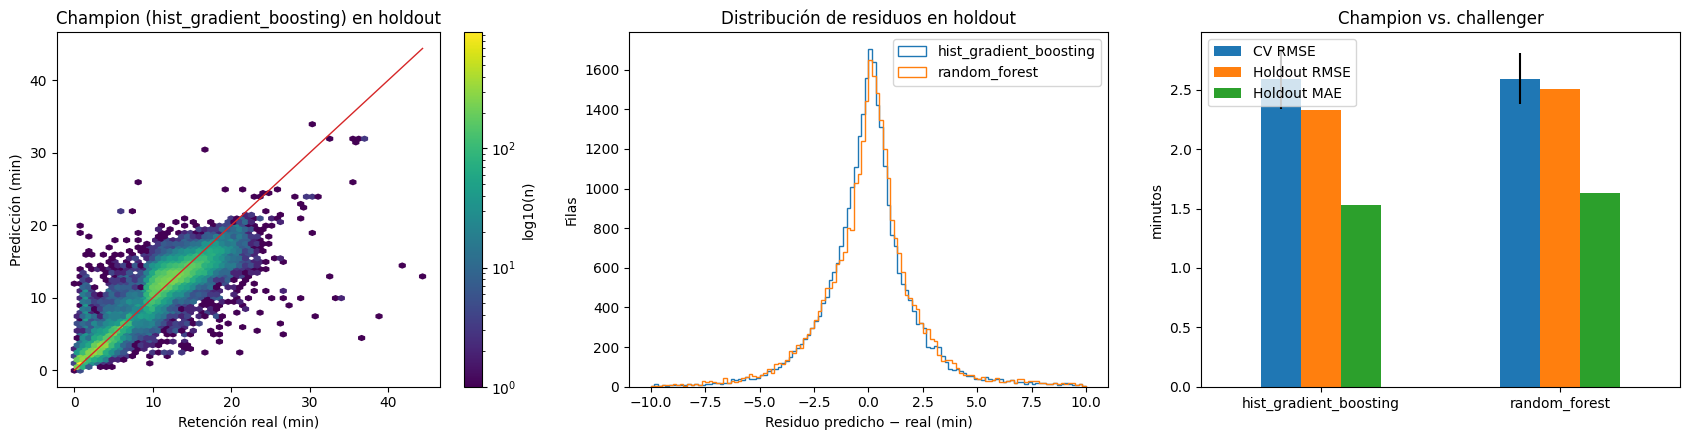

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
champion_prediction = trained[champion_family]["prediction"]
hb = axes[0].hexbin(y_test_array, champion_prediction, gridsize=60, bins="log", cmap="viridis")
limit = [0, float(max(y_test_array.max(), champion_prediction.max()))]
axes[0].plot(limit, limit, color="tab:red", lw=1)
axes[0].set(xlabel="Retención real (min)", ylabel="Predicción (min)", title=f"Champion ({champion_family}) en holdout")
fig.colorbar(hb, ax=axes[0], label="log10(n)")
for family in (champion_family, challenger_family):
    axes[1].hist(trained[family]["prediction"] - y_test_array, bins=120, range=(-10, 10), histtype="step", lw=1.5, label=family)
axes[1].set(xlabel="Residuo predicho − real (min)", ylabel="Filas", title="Distribución de residuos en holdout")
axes[1].legend()
summary_plot = pd.DataFrame({
    "CV RMSE": [trained[f]["selection_sample_cv_rmse_mean"] for f in (champion_family, challenger_family)],
    "Holdout RMSE": [trained[f]["holdout_rmse"] for f in (champion_family, challenger_family)],
    "Holdout MAE": [trained[f]["holdout_mae"] for f in (champion_family, challenger_family)],
}, index=[champion_family, challenger_family])
summary_plot.plot(kind="bar", ax=axes[2], rot=0, yerr=pd.DataFrame({"CV RMSE": [trained[f]["selection_sample_cv_rmse_std"] for f in (champion_family, challenger_family)]}, index=summary_plot.index).reindex(columns=summary_plot.columns).fillna(0))
axes[2].set(ylabel="minutos", title="Champion vs. challenger")
plt.tight_layout()
plt.show()

### Error de un par vs. error de una predicción, y comparación de reglas

La alerta compara **dos** predicciones, por lo que su error es mayor que el de una sola (en teoría ≈ √2 ≈ 1,41 × RMSE si los errores fueran independientes). Aquí se mide el factor real con las predicciones fuera de pliegue usadas para calibrar.

Después se compara, **sobre los mismos pares del holdout**, la regla elegida (intervalo del 95% calibrado) con la alternativa 2×RMSE (escalada a un par) y con el umbral fijo original de 0,5 min del PSet 1. Los umbrales se fijan con el RMSE fuera de pliegue, no con el holdout. Esta tabla **no** se usa para cambiar de regla: muestra el costo de la elegida.

,valor
RMSE_una_prediccion_OOF,2.729
RMSE_diferencia_de_un_par_OOF,4.170
factor_medido,1.528
factor_teorico_sqrt2,1.414


,umbral_min,alert_rate,recall,false_negative_rate,precision,false_alert_share
regla,,,,,,
intervalo 95% calibrado (elegida),9.079,0.912,0.991,0.009,0.203,0.797
2×RMSE×√2 (alternativa),7.719,0.876,0.984,0.016,0.210,0.790
1×RMSE×√2,3.860,0.619,0.919,0.081,0.277,0.723
"0,5 min fijo (PSet 1 original)",0.500,0.132,0.349,0.651,0.493,0.507


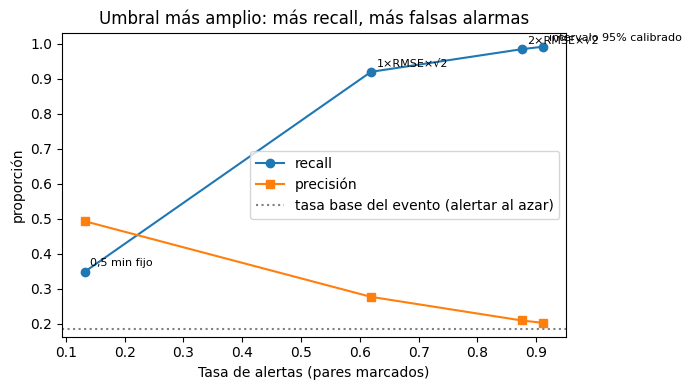

In [8]:
pair_factor = pd.Series({
    "RMSE_una_prediccion_OOF": interval["single_prediction_rmse"],
    "RMSE_diferencia_de_un_par_OOF": interval["pair_difference_rmse"],
    "factor_medido": interval["pair_to_single_error_ratio"],
    "factor_teorico_sqrt2": np.sqrt(2),
}).round(3)
display(pair_factor.to_frame("valor"))

oof_rmse = interval["single_prediction_rmse"]
alert_rules = compare_alert_rules(
    y_test_array, champion_prediction,
    chromatographic_condition_groups(X_test), groups_test,
    {
        "intervalo 95% calibrado (elegida)": interval["pair_error_radius"],
        "2×RMSE×√2 (alternativa)": 2 * oof_rmse * np.sqrt(2),
        "1×RMSE×√2": oof_rmse * np.sqrt(2),
        "0,5 min fijo (PSet 1 original)": COELUTION_WINDOW_MIN,
    },
    random_state=42,
)
display(alert_rules.round(3))
alert_rules.to_csv(docs / "reglas_alerta.csv")
client.log_text(trained[champion_family]["run_id"], alert_rules.to_csv(), "business/reglas_alerta.csv")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alert_rules["alert_rate"], alert_rules["recall"], marker="o", label="recall")
ax.plot(alert_rules["alert_rate"], alert_rules["precision"], marker="s", label="precisión")
ax.axhline(business_proxy["proxy_event_base_rate"], color="gray", ls=":", label="tasa base del evento (alertar al azar)")
for name, row in alert_rules.iterrows():
    ax.annotate(name.split(" (")[0], (row["alert_rate"], row["recall"]), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set(xlabel="Tasa de alertas (pares marcados)", ylabel="proporción", title="Umbral más amplio: más recall, más falsas alarmas")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura de las reglas de alerta.**

- **Factor del par:** el error de la diferencia entre dos predicciones es **1,53×** el de una sola (RMSE OOF 4,17 vs. 2,73 min). Es cercano al √2 ≈ 1,41 teórico y algo mayor porque los errores no son del todo independientes ni homogéneos entre condiciones. Por eso el intervalo se calibra con datos y no con una fórmula.
- **Regla elegida (intervalo del 95%):** alerta el 99,1% de los pares que realmente eluyen a ≤ 0,5 min (solo 0,9% de falsos negativos), pero marca el 91% de todos los pares. Su precisión (20%) apenas supera la tasa base del evento (18,7%): **la alerta casi no discrimina**.
- **Más amplio = más falsas alarmas:** al pasar de 1×RMSE×√2 al intervalo del 95%, el recall sube de 92% a 99%, pero las alertas suben de 62% a 91%.
- **0,5 min fijo:** reduce las alertas al 13%, pero pierde el 65% de las coeluciones, que es el error más costoso. Por eso no se usa como regla de alerta.

**Conclusión de negocio:** se mantiene el intervalo del 95% porque prioriza no omitir coeluciones, como se acordó. Con un RMSE de 2,3 min, el modelo **todavía no reduce corridas** en la tarea de detectar coeluciones de 0,5 min. Sí sirve como estimación gruesa de la retención y del orden de elución. Para que la alerta sea útil, el error de un par debería acercarse a la ventana de 0,5 min; la meta del PSet 1 (RMSE ≤ 0,5) apuntaba a eso. El ahorro del 30% sigue siendo una hipótesis.

### Comparación con la meta del PSet 1

In [9]:
pset1_goal = pd.DataFrame({
    "meta_PSet1": [0.5, 0.90],
    "champion_holdout": [trained[champion_family]["holdout_rmse"], r2_score(y_test_array, champion_prediction)],
}, index=["RMSE (min) ≤", "R² ≥"])
pset1_goal["cumple"] = [pset1_goal.iloc[0, 1] <= pset1_goal.iloc[0, 0], pset1_goal.iloc[1, 1] >= pset1_goal.iloc[1, 0]]
display(pset1_goal.round(3))
for name in ("holdout_r2",):
    client.log_metric(trained[champion_family]["run_id"], name, float(r2_score(y_test_array, champion_prediction)))
    client.log_metric(trained[challenger_family]["run_id"], name, float(r2_score(y_test_array, trained[challenger_family]["prediction"])))

,meta_PSet1,champion_holdout,cumple
RMSE (min) ≤,0.5,2.329,False
R² ≥,0.9,0.828,False


## 4. Costo y explicabilidad

La importancia por permutación se calcula sobre 3.000 filas de la muestra de **entrenamiento** (no del holdout), a dos niveles: (a) por columna cruda de entrada, que agrupa todos los descriptores derivados de esa columna, y (b) por feature derivada.

,aumento_rmse_min,desv
smiles,3.315,0.035
flujo_ml_min,3.275,0.061
fase_movil,0.615,0.014
tipo_columna,0.000,0.000


,aumento_rmse_min,desv
flow_ml_min,3.275,0.061
mol_logp,2.558,0.050
mol_tpsa,0.787,0.016
elu_b_meoh,0.514,0.025
mol_h_donors,0.508,0.021
mol_weight,0.385,0.022
mol_fraction_csp3,0.326,0.020
elu_b_acn,0.186,0.018


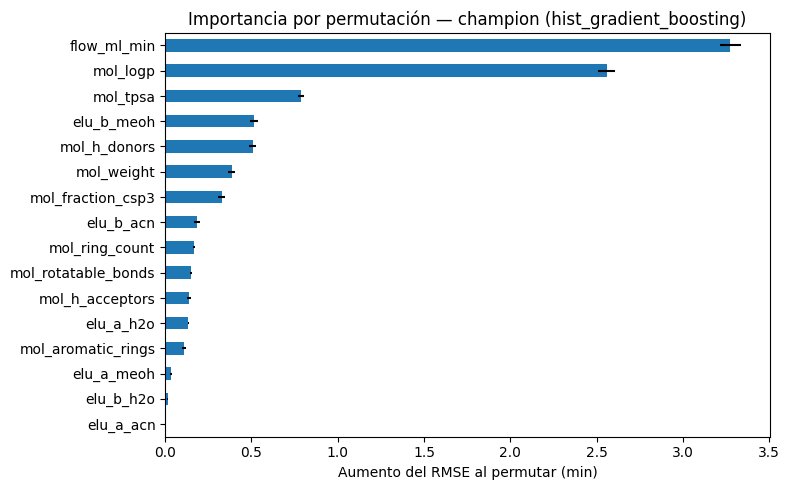

,entrenamiento_s,inferencia_ms_por_1000_filas,tamano_modelo_MB
modelo,,,
hist_gradient_boosting,45.90,366.94,0.73
random_forest,49.21,425.55,158.73


In [10]:
from sklearn.inspection import permutation_importance

explain_rows = X_oof.sample(3000, random_state=42)
explain_y = y_oof.loc[explain_rows.index]
rmse_scorer = SCORING["rmse"]
raw_importance = permutation_importance(champion, explain_rows, explain_y, scoring=rmse_scorer, n_repeats=5, random_state=42, n_jobs=1)
raw_table = pd.DataFrame({"aumento_rmse_min": raw_importance.importances_mean, "desv": raw_importance.importances_std}, index=explain_rows.columns).sort_values("aumento_rmse_min", ascending=False)
display(raw_table.round(3))

derived_rows = champion.named_steps["features"].transform(explain_rows)
feature_importance = permutation_importance(champion[1:], derived_rows, explain_y, scoring=rmse_scorer, n_repeats=5, random_state=42, n_jobs=1)
feature_table = pd.DataFrame({"aumento_rmse_min": feature_importance.importances_mean, "desv": feature_importance.importances_std}, index=derived_rows.columns).sort_values("aumento_rmse_min")
display(feature_table.sort_values("aumento_rmse_min", ascending=False).head(8).round(3))
ax = feature_table["aumento_rmse_min"].plot(kind="barh", xerr=feature_table["desv"], figsize=(8, 5), title=f"Importancia por permutación — champion ({champion_family})")
ax.set_xlabel("Aumento del RMSE al permutar (min)")
plt.tight_layout()
plt.show()

artifact_sizes = {}
for family in (champion_family, challenger_family):
    files = client.list_artifacts(trained[family]["run_id"], "model")
    artifact_sizes[family] = sum((item.file_size or 0) for item in files) / 1e6
cost_table = holdout_table[["entrenamiento_s", "inferencia_ms_por_1000_filas"]].assign(tamano_modelo_MB=pd.Series(artifact_sizes))
display(cost_table.round(2))
clear_feature_caches()
_ = gc.collect()

## Decisión

In [11]:
champion_version = client.get_model_version_by_alias(model_name, "champion")
challenger_version = client.get_model_version_by_alias(model_name, "challenger")
decision = pd.DataFrame([
    {"alias": "champion", "modelo": champion_family, "version": champion_version.version, "run_id": champion_version.run_id,
     "holdout_rmse": trained[champion_family]["holdout_rmse"], "holdout_mae": trained[champion_family]["holdout_mae"],
     "holdout_r2": r2_score(y_test_array, champion_prediction),
     "recall_proxy_negocio": business_proxy["coelution_proxy_recall"], "precision_proxy_negocio": business_proxy["coelution_proxy_precision"]},
    {"alias": "challenger", "modelo": challenger_family, "version": challenger_version.version, "run_id": challenger_version.run_id,
     "holdout_rmse": trained[challenger_family]["holdout_rmse"], "holdout_mae": trained[challenger_family]["holdout_mae"],
     "holdout_r2": r2_score(y_test_array, trained[challenger_family]["prediction"]),
     "recall_proxy_negocio": np.nan, "precision_proxy_negocio": np.nan},
])
display(decision.round(4))
assert champion_version.run_id == trained[champion_family]["run_id"]

,alias,modelo,version,run_id,holdout_rmse,holdout_mae,holdout_r2,recall_proxy_negocio,precision_proxy_negocio
0,champion,hist_gradient_boosting,5,04483473d3314b51b7ee40f03ca90c94,2.3290,1.5293,0.8284,0.9911,0.2029
1,challenger,random_forest,7,b49f230a7813494481c464fbce79cef5,2.5062,1.6334,0.8013,NaN,NaN


**Por qué gana HistGradientBoosting.**

1. **CV:** empata con Random Forest (2,592 ± 0,250 vs. 2,593 ± 0,216 min). La diferencia, 0,0015 min, es mucho menor que la desviación entre pliegues, así que el CV por sí solo no separa a los modelos. HGB queda primero por un margen mínimo.
2. **Holdout (evaluación única):** HGB obtiene RMSE 2,329 y MAE 1,529 min; RF, 2,506 y 1,633. HGB también tiene menos errores mayores de 2 min (25,5% vs. 27,5%). El holdout confirma el orden del CV, pero no se usó para cambiarlo.
3. **Costo:** el artefacto de HGB pesa 0,73 MB frente a 159 MB del bosque. HGB predice más rápido (≈367 vs. ≈426 ms por 1.000 filas, con RDKit incluido) y no necesitó el límite `max_samples` para poder serializarse.
4. **Explicabilidad:** la importancia por permutación muestra que la predicción depende sobre todo del flujo (+3,3 min de RMSE al permutarlo), de la hidrofobicidad (LogP, +2,6) y de la polaridad (TPSA, donadores de H). Esto concuerda con la química de fase reversa. `tipo_columna` tiene importancia 0 porque el modelo no la usa. Para una predicción individual se pueden mostrar esos descriptores; la importancia es global y no causal.
5. **Métrica de negocio (proxy):** con el intervalo pairwise del 95%, el champion alerta el 99,1% de los pares que eluyen a ≤ 0,5 min (falsos negativos 0,9%), pero marca el 91% de los pares, con precisión del 20% frente a una tasa base del 18,7%. El modelo gana la comparación técnica, pero su incertidumbre todavía es demasiado grande para que la alerta ahorre corridas. R² en el holdout: 0,828 (HGB) vs. 0,801 (RF); ninguno alcanza la meta del PSet 1 (RMSE ≤ 0,5 y R² ≥ 0,90).

Random Forest queda como **challenger** (versión 7); el champion es la versión 5 del registro `qsrr-predict-modelo`.

## Interpretación y monitoreo

**Regla de alerta (punto 1 acordado con el profesor):** una sola regla, el intervalo de predicción del 95% de la diferencia entre dos tiempos de retención, calibrado con residuos fuera de pliegue. El **evento** que se evalúa es químico e independiente del modelo: |Δt real| ≤ 0,5 min en la misma condición. RepoRT no contiene resolución ni ancho de pico, así que es un proxy de coelución, no una coelución confirmada.

**Alcance (puntos 2–4):** la validación se limita a RepoRT C18. No hay un laboratorio con corridas locales; el ahorro del 30% sigue siendo una hipótesis y la línea base de solvente (mL/min × corridas preliminares) necesita el número de corridas que solo daría un piloto.

**Monitoreo (punto 5):**

| Qué | Requiere el tiempo real | Frecuencia | Umbral de revisión |
|---|---|---|---|
| Deriva de descriptores (PSI) y faltantes | No | En cada lote de moléculas nuevas (como mínimo semanal, igual que la ingesta de Kestra) | PSI > 0,2 en alguna feature o +5 puntos de faltantes |
| RMSE, MAE y cobertura del intervalo | Sí: el laboratorio lo mide al inyectar el método | Se registra el mismo día de la corrida; se recalcula al acumular **30 compuestos medidos** o cada mes, lo que ocurra después | RMSE > 3,09 min (CV + 2σ) o cobertura < 90% → revisar o reentrenar |

La celda de deriva compara muestras de entrenamiento y holdout sin usar el target (PSI máximo ≈ 0,008). Es una demostración offline del indicador, no un monitor de producción.